# Our conv4 ensemble trained **in-domain** on the clean-vein-masks dataset (`Processed_Dataset_v3_s7`)

**Method (same as `resnet50_conv4_ensemble_reffree.ipynb`):** frozen ImageNet ResNet50 → `conv4_block6_out` → global average pooling (1024 features per frame) → average of three L2 logistic regressions (`C = 0.01`):
(1) all frames, (2) one per landmark (dorsal / wrist), (3) original + horizontally flipped frames with flip TTA. Trained **frame by frame**.

**Data / protocol (same as `h2opulse_model_experiment.ipynb` §6 / §6e-2):** users and hydrated-vs-reference folders from `users_list_final.csv`, first 5 frames per modality (L/R dorsal, L/R wrist), **GroupKFold(5) by user** over the sorted user list (identical folds), visit needs ≥ 2 modalities.

**Per outer fold:** the ensemble is trained on the training users only. The Youden threshold (recall weight 1.25, clipped to [0.05, 0.95]) is chosen on the **training users' out-of-fold predictions** (inner 4-fold GroupKFold), never on the test users. Pooled OOF uses the mean fold threshold (their §6 rule). Fixed t = 0.5 is also reported.

**Test-time variants:** A. best frame (`*_001`) · B. random frame (10 seeds) · C. all frame combinations (625 per visit) · **D. session level = mean of all frames of the visit (primary).**

**Reference (their morphology LR, §6, same folds):** pooled OOF accuracy 0.7365, AUROC 0.7818; fold mean accuracy 0.757 ± 0.049.

Run from the `H2OPulse/` folder; data is found automatically under `H2OPulse/external/`. Outputs go to `H2OPulse/outputs/external_trained/`.

In [1]:
# Run once if TensorFlow / scikit-learn are missing, then restart the kernel
# %pip install "tensorflow[and-cuda]" scikit-learn matplotlib pandas

In [2]:
# --- Environment check ---
import os, socket
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf

print("Host:", socket.gethostname())
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - running on CPU (slower, but feature extraction still works)")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError as e:
        print("Could not set memory growth:", e)

I0000 00:00:1795505743.343855 3690573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795505799.012745 3690573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Host: gpu10
TensorFlow: 2.22.0-rc1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# --- Configuration ---
PROJECT_DIR = os.getcwd()                                   # the H2OPulse folder
EXT_ROOT = os.path.join(PROJECT_DIR, "external")
OUT_DIR = os.path.join(PROJECT_DIR, "outputs", "external_trained")
os.makedirs(OUT_DIR, exist_ok=True)


def _find(root, name, want_dir):
    for dirpath, dirnames, filenames in os.walk(root):
        if name in (dirnames if want_dir else filenames):
            return os.path.join(dirpath, name)
    return None


DATA_ROOT = _find(EXT_ROOT, "Processed_Dataset_v3_s7", want_dir=True)
CSV_PATH = _find(EXT_ROOT, "users_list_final.csv", want_dir=False) or _find(EXT_ROOT, "users_list_v3.csv", want_dir=False)
if DATA_ROOT is None or CSV_PATH is None:
    raise FileNotFoundError(f"Could not find Processed_Dataset_v3_s7/ and users_list_final.csv under {EXT_ROOT}")

MODALITIES = ["left_dorsal", "right_dorsal", "left_wrist", "right_wrist"]
DORSAL_MODS = ["left_dorsal", "right_dorsal"]
LANDMARKS = ["dorsal", "wrist"]
N_FRAMES = 5
MIN_MODALITIES = 2

IMG_SIZE = (224, 224)
FEATURE_LAYER = "conv4_block6_out"
LOGREG_C = 0.01
BATCH_SIZE = 32

N_SPLITS = 5            # outer GroupKFold (same as their notebook)
INNER_SPLITS = 4        # inner GroupKFold on training users, used only to choose the threshold
SEED = 801              # their SEED -> same random-frame draws
N_RANDOM_REPEATS = 10
FIXED_THRESHOLDS = [0.5]

FEATURES_CACHE = os.path.join(OUT_DIR, f"features_{FEATURE_LAYER}_{IMG_SIZE[0]}.npz")
FEATURES_FLIP_CACHE = os.path.join(OUT_DIR, f"features_{FEATURE_LAYER}_{IMG_SIZE[0]}_hflip.npz")
FINAL_MODEL_PATH = os.path.join(OUT_DIR, "conv4_ensemble_external.keras")
FINAL_CONFIG_PATH = os.path.join(OUT_DIR, "conv4_ensemble_external_config.json")

print("DATA_ROOT:", DATA_ROOT)
print("CSV      :", CSV_PATH)
print("OUT_DIR  :", OUT_DIR)

DATA_ROOT: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/external/clean_vein_masks/Processed_Dataset_v3_s7
CSV      : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/external/user_selection/users_list_final.csv
OUT_DIR  : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained


In [4]:
import glob, json
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score, auc, balanced_accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

tf.keras.utils.set_random_seed(SEED)

## 1. Users and frames (same selection and folder rules as their notebook)

In [5]:
raw = pd.read_csv(CSV_PATH)
users_df = raw.iloc[:, :5].copy()
users_df.columns = ["user_id", "ok_d", "hyd_ref_d", "ok_w", "hyd_ref_w"]
_ok = {(1, 1), (1, 0), (0, 1), (1, -1), (-1, 1)}                 # assign_weights_and_filter in their §2
users_df = users_df[[(d, w) in _ok for d, w in zip(users_df.ok_d, users_df.ok_w)]].reset_index(drop=True)
user_meta = users_df.set_index("user_id").to_dict("index")
users = np.array(sorted(set(users_df.user_id)))
print(f"Selected users: {len(users)}")

rows, missing = [], []
for uid in users:
    meta = user_meta[uid]
    for label, state in [(1, "dehydrated"), (0, "hydrated")]:
        for mod in MODALITIES:
            use_h = int(meta["hyd_ref_d" if mod in DORSAL_MODS else "hyd_ref_w"])
            sub = "dehydrated" if state == "dehydrated" else ("hydrated" if use_h else "reference")
            folder = os.path.join(DATA_ROOT, uid, sub, mod)
            paths = sorted(glob.glob(os.path.join(folder, "*.png")))[:N_FRAMES]
            if not paths:
                missing.append(folder)
            for fi, p in enumerate(paths):
                rows.append({"user_id": uid, "label": label, "modality": mod,
                             "landmark": "dorsal" if mod in DORSAL_MODS else "wrist",
                             "frame_idx": fi, "path": p})
frames = pd.DataFrame(rows)
if missing:
    print(f"[WARN] {len(missing)} empty/missing modality folders (e.g. {missing[0]})")

y_all = frames.label.values.astype(int)
user_arr = frames.user_id.values
lm_arr = frames.landmark.values
print(f"Frames: {len(frames)} | scenarios: {frames.groupby(['user_id', 'label', 'modality']).ngroups} "
      f"| visits: {frames.groupby(['user_id', 'label']).ngroups}")
print(f"Class balance (frames): hydrated={int((y_all == 0).sum())}  dehydrated={int((y_all == 1).sum())}")

Selected users: 74
Frames: 2960 | scenarios: 592 | visits: 148
Class balance (frames): hydrated=1480  dehydrated=1480


## 2. Features: frozen ResNet50 → conv4 → global average pooling (original + flipped, cached)

In [6]:
_base = ResNet50(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
_base.trainable = False
feature_extractor = keras.Model(
    _base.input,
    layers.GlobalAveragePooling2D(name="gap")(_base.get_layer(FEATURE_LAYER).output),
    name=f"resnet50_{FEATURE_LAYER}_gap",
)


def load_image(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.cast(tf.image.resize(img, IMG_SIZE), tf.float32)
    return preprocess_input(img)


def image_dataset(paths, flip=False):
    fn = (lambda p: tf.image.flip_left_right(load_image(p))) if flip else load_image
    return (tf.data.Dataset.from_tensor_slices(np.asarray(paths, dtype=object))
            .map(fn, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


def cached_features(cache_path, paths, flip):
    if os.path.exists(cache_path):
        c = np.load(cache_path, allow_pickle=True)
        if list(c["paths"]) == list(paths):
            print("Loaded cached features:", cache_path)
            return c["X"]
    X = feature_extractor.predict(image_dataset(paths, flip=flip), verbose=1)
    np.savez_compressed(cache_path, X=X, paths=np.asarray(paths, dtype=object))
    print("Saved features:", cache_path)
    return X


X_all = cached_features(FEATURES_CACHE, frames.path.values, flip=False)
X_flip = cached_features(FEATURES_FLIP_CACHE, frames.path.values, flip=True)
print("Feature matrices:", X_all.shape, X_flip.shape)

93/93 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step
Saved features: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained/features_conv4_block6_out_224.npz
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Saved features: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained/features_conv4_block6_out_224_hflip.npz
Feature matrices: (2960, 1024) (2960, 1024)


## 3. Ensemble, threshold and visit helpers

In [7]:
def make_classifier():
    return make_pipeline(StandardScaler(), LogisticRegression(C=LOGREG_C, max_iter=3000))


def fit_ensemble(idx):
    idx = np.asarray(idx)
    ens = {"all": make_classifier().fit(X_all[idx], y_all[idx]), "landmark": {}}
    for lm in LANDMARKS:
        j = idx[lm_arr[idx] == lm]
        ens["landmark"][lm] = make_classifier().fit(X_all[j], y_all[j])
    ens["flip"] = make_classifier().fit(np.vstack([X_all[idx], X_flip[idx]]), np.r_[y_all[idx], y_all[idx]])
    return ens


def predict_ensemble(ens, idx):
    idx = np.asarray(idx)
    X, Xf, lms = X_all[idx], X_flip[idx], lm_arr[idx]
    p_all = ens["all"].predict_proba(X)[:, 1]
    p_lm = np.zeros(len(idx))
    for lm, m in ens["landmark"].items():
        k = lms == lm
        if k.any():
            p_lm[k] = m.predict_proba(X[k])[:, 1]
    p_flip = 0.5 * (ens["flip"].predict_proba(X)[:, 1] + ens["flip"].predict_proba(Xf)[:, 1])
    return (p_all + p_lm + p_flip) / 3


def youden_threshold(y_true, y_prob, recall_weight=1.25):       # identical to their notebook
    if len(set(y_true)) < 2:
        return 0.5
    fpr, tpr, thresh = roc_curve(y_true, y_prob)
    idx = int(np.argmax(recall_weight * tpr - fpr))
    return float(np.clip(float(thresh[idx]), 0.05, 0.95))


METRICS = ["Accuracy", "Precision", "F1", "Recall (Sensitivity)", "Specificity", "Balanced Accuracy", "AUROC"]


def metrics(y, p, t):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= t).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y, pred, zero_division=0),
        "Specificity": recall_score(y, pred, pos_label=0, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "AUROC": roc_auc_score(y, p) if len(set(y)) > 1 else 0.5,
    }


def scen_from(prob, idx):
    # scenario (user, label, modality) -> frame probabilities in frame order
    sub = frames.iloc[idx].assign(p=prob[idx]).sort_values("frame_idx")
    return {(u, int(l), m): g.p.values for (u, l, m), g in sub.groupby(["user_id", "label", "modality"])}


def build_samples(scen, mode, choice=None):
    # visit (user, label) -> array of sample probabilities (A/B/D: 1 per visit, C: 625 per visit)
    per_visit = defaultdict(list)
    for k in sorted(scen):
        per_visit[(k[0], k[1])].append(k)
    out = {}
    for v, keys in per_visit.items():
        if len(keys) < MIN_MODALITIES:
            continue
        arrs = [scen[k] for k in keys]
        if mode == "frame":
            out[v] = np.array([np.mean([scen[k][choice[k]] for k in keys])])
        elif mode == "combos":
            out[v] = np.mean(np.stack(np.meshgrid(*arrs, indexing="ij")), axis=0).ravel()
        elif mode == "session":
            out[v] = np.array([np.concatenate(arrs).mean()])
    return out


def stack_samples(s):
    keys = sorted(s)
    if not keys:
        return np.array([]), np.array([])
    return (np.concatenate([np.full(len(s[k]), k[1]) for k in keys]),
            np.concatenate([s[k] for k in keys]))


all_scen_keys = sorted({(u, int(l), m) for u, l, m in frames[["user_id", "label", "modality"]].itertuples(index=False)})
n_frames_of = frames.groupby(["user_id", "label", "modality"]).size().to_dict()

## 4. Cross-validation: train per fold, test on held-out users

In [8]:
outer = list(GroupKFold(n_splits=N_SPLITS).split(users, groups=users))   # same call as their notebook
oof_test = np.full(len(y_all), np.nan)
train_scens, test_scens = [], []

for f, (tr_u_idx, te_u_idx) in enumerate(outer, 1):
    tr_users, te_users = users[tr_u_idx], users[te_u_idx]
    tr_idx = np.where(np.isin(user_arr, tr_users))[0]
    te_idx = np.where(np.isin(user_arr, te_users))[0]
    assert not set(user_arr[tr_idx]) & set(user_arr[te_idx]), "user leakage"

    # (a) model on all training users -> held-out test users
    ens = fit_ensemble(tr_idx)
    oof_test[te_idx] = predict_ensemble(ens, te_idx)

    # (b) out-of-fold predictions for the training users (inner GroupKFold) -> used only for the threshold
    inner_p = np.full(len(y_all), np.nan)
    for itr, ite in GroupKFold(n_splits=INNER_SPLITS).split(tr_idx, groups=user_arr[tr_idx]):
        inner_p[tr_idx[ite]] = predict_ensemble(fit_ensemble(tr_idx[itr]), tr_idx[ite])

    train_scens.append(scen_from(inner_p, tr_idx))
    test_scens.append(scen_from(oof_test, te_idx))
    print(f"fold {f}: train users={len(tr_users)} ({len(tr_idx)} frames) | test users={len(te_users)} "
          f"({len(te_idx)} frames) | test frame AUROC={roc_auc_score(y_all[te_idx], oof_test[te_idx]):.3f}")

print(f"\nPooled frame-level AUROC (out-of-fold, no threshold): {roc_auc_score(y_all, oof_test):.3f}")
frames.assign(oof_prob=oof_test).to_csv(os.path.join(OUT_DIR, "frame_oof_probs.csv"), index=False)


def eval_experiment(mode, choice=None):
    rows, fold_t, oy, op = [], [], [], []
    for f in range(N_SPLITS):
        tr_y, tr_p = stack_samples(build_samples(train_scens[f], mode, choice))
        te_s = build_samples(test_scens[f], mode, choice)
        te_y, te_p = stack_samples(te_s)
        t = youden_threshold(tr_y, tr_p)
        fold_t.append(t); oy.append(te_y); op.append(te_p)
        base = {"fold": f + 1, "n_test_visits": len(te_s), "n_test_samples": len(te_y)}
        rows.append({**base, "threshold": "youden_train", "t": t, **metrics(te_y, te_p, t)})
        for tf_ in FIXED_THRESHOLDS:
            rows.append({**base, "threshold": f"fixed_{tf_}", "t": tf_, **metrics(te_y, te_p, tf_)})
    oy, op = np.concatenate(oy), np.concatenate(op)
    t_mean = float(np.mean(fold_t))
    pooled = {"youden_train": metrics(oy, op, t_mean)}
    for tf_ in FIXED_THRESHOLDS:
        pooled[f"fixed_{tf_}"] = metrics(oy, op, tf_)
    return pd.DataFrame(rows), pooled, t_mean


summary_rows, fold_tables = [], []


def add_summary(name, fdf, pooled, t_mean, repeat_std=None):
    for thr in fdf.threshold.unique():
        sub = fdf[fdf.threshold == thr]
        row = {"Experiment": name, "threshold": thr,
               "t (mean fold)": t_mean if thr == "youden_train" else float(thr.split("_", 1)[1])}
        for m in METRICS:
            row[f"{m} (fold mean)"] = sub[m].mean()
            row[f"{m} (fold std)"] = sub[m].std()
            row[f"{m} (pooled OOF)"] = pooled[thr][m]
            if repeat_std is not None:
                row[f"{m} (std across repeats)"] = repeat_std[thr][m]
        summary_rows.append(row)


# A. best frame (*_001)
best_idx = {k: 0 for k in all_scen_keys}
fdf, pooled, t_ = eval_experiment("frame", best_idx)
fdf.insert(0, "experiment", "A. Best frame"); fold_tables.append(fdf)
add_summary("A. Best frame (*_001)", fdf, pooled, t_)

# B. random frame, 10 seeds (same draws as their notebook)
rep_f, rep_p, rep_t, rep_means = [], [], [], defaultdict(list)
for r in range(N_RANDOM_REPEATS):
    rng = np.random.default_rng(SEED + r)
    rand_idx = {k: int(rng.integers(n_frames_of[k])) for k in all_scen_keys}
    fdf_r, pooled_r, t_r = eval_experiment("frame", rand_idx)
    fdf_r.insert(0, "experiment", "B. Random frame"); fdf_r.insert(1, "repeat", r)
    rep_f.append(fdf_r); rep_p.append(pooled_r); rep_t.append(t_r)
    for thr in fdf_r.threshold.unique():
        rep_means[thr].append(fdf_r[fdf_r.threshold == thr][METRICS].mean())
fdf_rand = pd.concat(rep_f, ignore_index=True); fold_tables.append(fdf_rand)
pooled_rand = {thr: {m: float(np.mean([p[thr][m] for p in rep_p])) for m in METRICS} for thr in rep_means}
rand_std = {thr: pd.DataFrame(v).std().to_dict() for thr, v in rep_means.items()}
add_summary(f"B. Random frame ({N_RANDOM_REPEATS} seeds)", fdf_rand, pooled_rand, float(np.mean(rep_t)), rand_std)

# C. all frame combinations
fdf, pooled, t_ = eval_experiment("combos")
fdf.insert(0, "experiment", "C. All frame combinations"); fold_tables.append(fdf)
add_summary("C. All frame combinations", fdf, pooled, t_)

# D. session level (primary)
fdf_D, pooled_D, t_D = eval_experiment("session")
fdf_D.insert(0, "experiment", "D. Session level"); fold_tables.append(fdf_D)
add_summary("D. Session level (mean of all frames)", fdf_D, pooled_D, t_D)

summary = pd.DataFrame(summary_rows)
pd.concat(fold_tables, ignore_index=True).to_csv(os.path.join(OUT_DIR, "cv_folds.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "cv_summary.csv"), index=False)
print("Saved cv_folds.csv / cv_summary.csv to", OUT_DIR)

fold 1: train users=59 (2360 frames) | test users=15 (600 frames) | test frame AUROC=0.634
fold 2: train users=59 (2360 frames) | test users=15 (600 frames) | test frame AUROC=0.588
fold 3: train users=59 (2360 frames) | test users=15 (600 frames) | test frame AUROC=0.657
fold 4: train users=59 (2360 frames) | test users=15 (600 frames) | test frame AUROC=0.605
fold 5: train users=60 (2400 frames) | test users=14 (560 frames) | test frame AUROC=0.697

Pooled frame-level AUROC (out-of-fold, no threshold): 0.634
Saved cv_folds.csv / cv_summary.csv to /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained


## 5. Results


Conv4 ensemble trained in-domain — fold mean — threshold: Youden on training users (inner OOF)
Experiment                                      Acc     Prec       F1      Rec     Spec   BalAcc    AUROC
--------------------------------------------------------------------------------------------------------
A. Best frame (*_001)                         0.696    0.679    0.703    0.747    0.646    0.696    0.747
B. Random frame (10 seeds)                    0.667    0.638    0.702    0.799    0.534    0.667    0.738
C. All frame combinations                     0.672    0.630    0.720    0.845    0.498    0.672    0.736
D. Session level (mean of all frames)         0.703    0.655    0.747    0.880    0.527    0.703    0.756

Conv4 ensemble trained in-domain — pooled OOF — threshold: Youden on training users (inner OOF)
Experiment                                      Acc     Prec       F1      Rec     Spec   BalAcc    AUROC
------------------------------------------------------------------

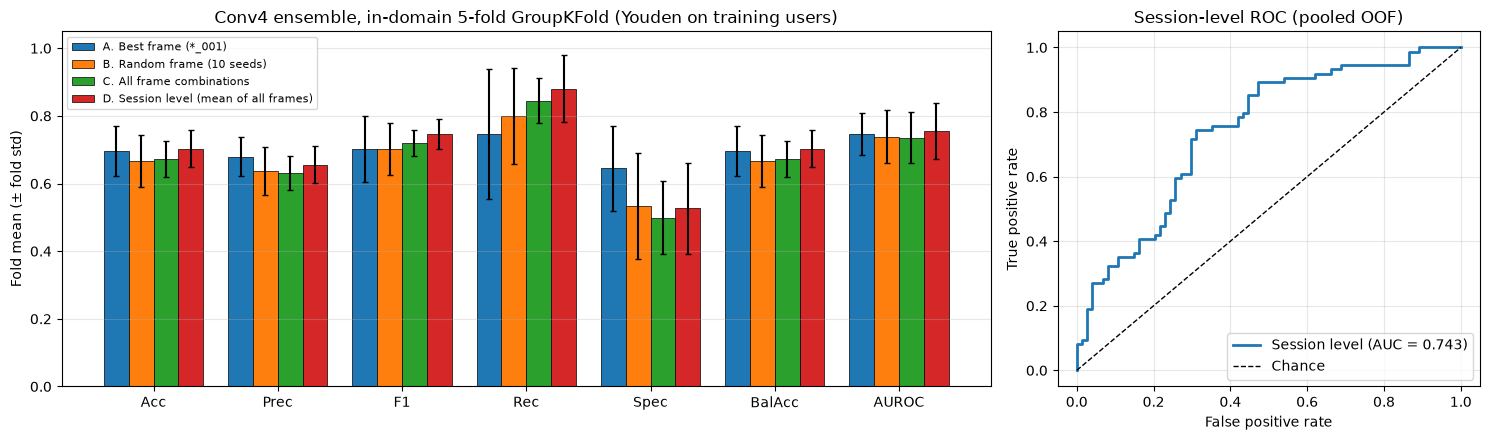

In [9]:
_short = {"Accuracy": "Acc", "Precision": "Prec", "F1": "F1", "Recall (Sensitivity)": "Rec",
          "Specificity": "Spec", "Balanced Accuracy": "BalAcc", "AUROC": "AUROC"}
_tags = {"youden_train": "Youden on training users (inner OOF)", "fixed_0.5": "fixed t=0.5"}

for thr in ["youden_train"] + [f"fixed_{t}" for t in FIXED_THRESHOLDS]:
    for kind in ["fold mean", "pooled OOF"]:
        print("\n" + "=" * 104)
        print(f"Conv4 ensemble trained in-domain — {kind} — threshold: {_tags.get(thr, thr)}")
        print("=" * 104)
        print(f"{'Experiment':<42}" + "".join(f"{_short[m]:>9}" for m in METRICS))
        print("-" * 104)
        for _, row in summary[summary.threshold == thr].iterrows():
            print(f"{row['Experiment']:<42}" + "".join(f"{row[f'{m} ({kind})']:>9.3f}" for m in METRICS))

# ---- headline: session level (D), Youden on training users ----
_D = fdf_D[fdf_D.threshold == "youden_train"]
print("\n" + "#" * 80)
print("SESSION LEVEL (D) — Youden threshold on training users")
print("#" * 80)
print(_D[["fold", "n_test_visits", "t", "Accuracy", "Precision", "Recall (Sensitivity)", "F1", "AUROC"]]
      .rename(columns={"Recall (Sensitivity)": "Recall"}).round(3).to_string(index=False))
print("\nMean ± SD across folds:")
for m, lab in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall (Sensitivity)", "recall"),
               ("F1", "F1"), ("AUROC", "AUC")]:
    print(f"  {lab:10s} {_D[m].mean():.3f} ± {_D[m].std():.3f}")
print(f"\nPooled over all visits (t = mean fold threshold {t_D:.3f}):")
for m, lab in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall (Sensitivity)", "recall"),
               ("F1", "F1"), ("AUROC", "AUC")]:
    print(f"  {lab:10s} {pooled_D['youden_train'][m]:.3f}")
print("\nReference — their morphology LR (§6, same folds): pooled accuracy 0.7365, AUROC 0.7818; "
      "fold-mean accuracy 0.757 ± 0.049")

_y = summary[summary.threshold == "youden_train"].set_index("Experiment")
_best = _y["Accuracy (fold mean)"].idxmax()
print(f"\nBest by fold-mean accuracy (Youden): {_best}  "
      f"(Acc {_y.loc[_best, 'Accuracy (fold mean)']:.3f}, AUROC {_y.loc[_best, 'AUROC (fold mean)']:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
w = 0.8 / len(_y)
xs = np.arange(len(METRICS))
for i, (name, row) in enumerate(_y.iterrows()):
    ax.bar(xs + (i - (len(_y) - 1) / 2) * w, [row[f"{m} (fold mean)"] for m in METRICS], w,
           yerr=[row[f"{m} (fold std)"] for m in METRICS], capsize=2, label=name, edgecolor="black", linewidth=0.5)
ax.set_xticks(xs); ax.set_xticklabels([_short[m] for m in METRICS])
ax.set_ylim(0, 1.05); ax.set_ylabel("Fold mean (± fold std)")
ax.set_title("Conv4 ensemble, in-domain 5-fold GroupKFold (Youden on training users)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
_vis = defaultdict(list)
for f in range(N_SPLITS):
    for k, v in build_samples(test_scens[f], "session").items():
        _vis["y"].append(k[1]); _vis["p"].append(v[0])
fpr, tpr, _ = roc_curve(_vis["y"], _vis["p"])
ax.plot(fpr, tpr, lw=2, label=f"Session level (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Session-level ROC (pooled OOF)"); ax.legend(loc="lower right"); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "cv_results.png"), dpi=150)
plt.show()

## 6. Train the final ensemble on all users and save one `.keras` file

In [10]:
final_ens = fit_ensemble(np.arange(len(y_all)))
DEPLOY_THRESHOLD = t_D        # mean of the fold Youden thresholds for session level (D)
print(f"Trained on {len(y_all)} frames from {len(users)} users | session-level deployment threshold = {DEPLOY_THRESHOLD:.3f}")


def to_dense(pipelines):
    W, B = [], []
    for pipe in pipelines:
        sc, lr = pipe.named_steps["standardscaler"], pipe.named_steps["logisticregression"]
        w = lr.coef_.ravel() / sc.scale_
        W.append(w)
        B.append(lr.intercept_[0] - np.sum(w * sc.mean_))
    return [np.stack(W, axis=1).astype("float32"), np.array(B, dtype="float32")]


img_in = keras.Input(shape=(*IMG_SIZE, 3), name="image")          # 224x224 RGB after resnet50.preprocess_input
lm_in = keras.Input(shape=(len(LANDMARKS),), name="landmark")      # one-hot in LANDMARKS order
feat = feature_extractor(img_in)
_W = IMG_SIZE[1]
hflip_matrix = layers.Dense(_W, use_bias=False, trainable=False, name="hflip_matrix")
img_flip = layers.Permute((1, 3, 2), name="hflip_back")(hflip_matrix(layers.Permute((1, 3, 2), name="hflip_to_w")(img_in)))
feat_flip = feature_extractor(img_flip)

head_all = layers.Dense(1, activation="sigmoid", name="head_all")
head_lm = layers.Dense(len(LANDMARKS), activation="sigmoid", name="head_per_landmark")
head_flip = layers.Dense(1, activation="sigmoid", name="head_flip")
p_all = head_all(feat)
p_lm = layers.Dot(axes=1, name="pick_landmark")([head_lm(feat), lm_in])
p_flip = layers.Average(name="flip_tta")([head_flip(feat), head_flip(feat_flip)])
out = layers.Average(name="ensemble")([p_all, p_lm, p_flip])
final_model = keras.Model({"image": img_in, "landmark": lm_in}, out, name="resnet50_conv4_ensemble_external")

hflip_matrix.set_weights([np.eye(_W, dtype="float32")[::-1]])
head_all.set_weights(to_dense([final_ens["all"]]))
head_lm.set_weights(to_dense([final_ens["landmark"][lm] for lm in LANDMARKS]))
head_flip.set_weights(to_dense([final_ens["flip"]]))


def model_dataset(paths, landmarks):
    onehot = np.eye(len(LANDMARKS), dtype="float32")[[LANDMARKS.index(l) for l in landmarks]]
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(paths, dtype=object), onehot))
    return (ds.map(lambda p, l: {"image": load_image(p), "landmark": l}, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


chk = np.random.default_rng(0).choice(len(frames), size=min(200, len(frames)), replace=False)
p_keras = final_model.predict(model_dataset(frames.path.values[chk], lm_arr[chk]), verbose=0).ravel()
p_sklearn = predict_ensemble(final_ens, chk)
print(f"Max |keras - sklearn| = {np.max(np.abs(p_keras - p_sklearn)):.2e}  (should be ~1e-5 or smaller)")

final_model.save(FINAL_MODEL_PATH)
_reloaded = keras.models.load_model(FINAL_MODEL_PATH)
_d = np.max(np.abs(_reloaded.predict(model_dataset(frames.path.values[chk], lm_arr[chk]), verbose=0).ravel() - p_keras))
json.dump({"session_threshold": DEPLOY_THRESHOLD, "landmarks": LANDMARKS, "img_size": list(IMG_SIZE),
           "feature_layer": FEATURE_LAYER, "logreg_C": LOGREG_C,
           "session_rule": "mean P(dehydrated) over all frames of a visit (>= 2 modalities)"},
          open(FINAL_CONFIG_PATH, "w"), indent=2)
print("Saved:", FINAL_MODEL_PATH, f"(reload check: max diff {_d:.1e})")
print("Saved:", FINAL_CONFIG_PATH)

Trained on 2960 frames from 74 users | session-level deployment threshold = 0.420
Max |keras - sklearn| = 1.25e-03  (should be ~1e-5 or smaller)
Saved: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained/conv4_ensemble_external.keras (reload check: max diff 0.0e+00)
Saved: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained/conv4_ensemble_external_config.json


## Using the saved model

```python
model = keras.models.load_model("outputs/external_trained/conv4_ensemble_external.keras")
p = model.predict(model_dataset(paths, landmarks)).ravel()   # landmarks: "dorsal" / "wrist" per frame
visit_is_dehydrated = p.mean() >= session_threshold          # threshold from conv4_ensemble_external_config.json
```
The model is trained on **all** 74 users of this dataset — use the cross-validation results above as its performance estimate.

Model: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained/conv4_ensemble_external.keras | session threshold learned on the external dataset = 0.420
Test data: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/Dataset
Subjects: 86 | frames: 3291 | scenarios: 688 | visits: 172
Frames per modality: {1: 3, 2: 5, 3: 28, 4: 66, 5: 586}
Example file names (first scenario): ['IMG_20240322_215533.jpg', 'IMG_20240322_215534.jpg', 'frame_21.jpg', 'frame_41.jpg', 'frame_66.jpg']
Running the external-trained ensemble on every H2OPulse frame...
103/103 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step
Frame-level AUROC (all frames, no threshold): 0.522
Re-scored best frame == first file in 23.7% of scenarios
Best-frame source: first_file
C: 172 visits | combinations per visit: min=75 max=625

External-trained ensemble on H2OPulse Dataset/ — fold mean — threshold: Youden on training subjects
Experiment                                      Acc     Prec       F1      Rec     Spec   BalAcc    AURO

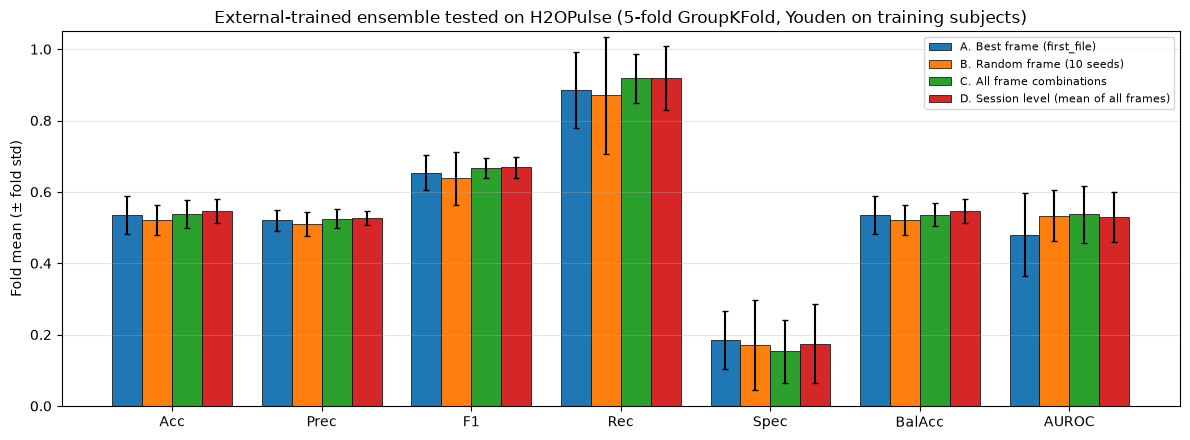

Saved results to /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/external_trained/test_on_h2opulse


In [12]:
# === 7. Reverse test: model trained on the external dataset, FROZEN, tested on the H2OPulse Dataset/ ===
# Same protocol as the earlier external test, with the datasets swapped:
#   up to 5 frames per modality (L/R dorsal, L/R wrist), GroupKFold(5) by subject over the sorted H2OPulse
#   subjects - the model is NOT retrained; folds only choose the Youden threshold on each fold's training subjects.
#   Fixed thresholds: 0.5 and the session threshold learned on the external dataset (zero-shot).
#   A. Best frame   B. Random frame (10 seeds)   C. All frame combinations   D. Session level (mean of all frames)
H2O_DATA_ROOT = os.path.join(PROJECT_DIR, "Dataset")
H2O_HANDS = ["left_hand", "right_hand"]
H2O_ROI_SUBDIR = "yolo_vein_roi"
BEST_FRAME_SOURCE = "first_file"   # "first_file" = first file in sorted order | "rescore" = DatasetCurator score
REV_OUT = os.path.join(OUT_DIR, "test_on_h2opulse")
os.makedirs(REV_OUT, exist_ok=True)

_cfg = json.load(open(FINAL_CONFIG_PATH))
EXT_SESSION_T = float(_cfg["session_threshold"])
REV_FIXED = [0.5, round(EXT_SESSION_T, 4)]
print("Model:", FINAL_MODEL_PATH, f"| session threshold learned on the external dataset = {EXT_SESSION_T:.3f}")
print("Test data:", H2O_DATA_ROOT)

# ---------------------------------------------------------------- frames ----
def _imgs(folder):
    if not os.path.isdir(folder):
        return []
    return sorted(os.path.join(folder, n) for n in os.listdir(folder)
                  if not n.startswith(".") and n.lower().endswith((".jpg", ".jpeg", ".png")))


h2o_subjects = np.array(sorted(d for d in os.listdir(H2O_DATA_ROOT)
                               if os.path.isdir(os.path.join(H2O_DATA_ROOT, d)) and not d.startswith(".")))
rows, empty = [], []
for uid in h2o_subjects:
    for label, state in [(1, "dehydrated"), (0, "hydrated")]:
        for hand in H2O_HANDS:
            for lm in LANDMARKS:
                mod = f"{hand.split('_')[0]}_{lm}"                     # left_dorsal, right_wrist, ...
                paths = _imgs(os.path.join(H2O_DATA_ROOT, uid, state, hand, lm, H2O_ROI_SUBDIR))[:N_FRAMES]
                if not paths:
                    empty.append((uid, state, mod))
                for fi, p in enumerate(paths):
                    rows.append({"user_id": uid, "label": label, "modality": mod, "landmark": lm,
                                 "frame_idx": fi, "frame_name": os.path.basename(p), "path": p})
h2o_frames = pd.DataFrame(rows)
if empty:
    print(f"[WARN] {len(empty)} empty/missing modality folders (e.g. {empty[0]})")
print(f"Subjects: {len(h2o_subjects)} | frames: {len(h2o_frames)} | "
      f"scenarios: {h2o_frames.groupby(['user_id', 'label', 'modality']).ngroups} | "
      f"visits: {h2o_frames.groupby(['user_id', 'label']).ngroups}")
print("Frames per modality:", h2o_frames.groupby(['user_id', 'label', 'modality']).size().value_counts().sort_index().to_dict())
print("Example file names (first scenario):", h2o_frames.groupby(['user_id', 'label', 'modality']).frame_name.apply(list).iloc[0])

# ---------------------------------------------------------------- predict every frame once ----
rev_model = keras.models.load_model(FINAL_MODEL_PATH)
print("Running the external-trained ensemble on every H2OPulse frame...")
h2o_frames["prob"] = rev_model.predict(model_dataset(h2o_frames.path.values, h2o_frames.landmark.values),
                                       verbose=1).ravel()
print(f"Frame-level AUROC (all frames, no threshold): {roc_auc_score(h2o_frames.label, h2o_frames.prob):.3f}")

rev_scen = {}
for key, sub in h2o_frames.sort_values("frame_idx").groupby(["user_id", "label", "modality"]):
    rev_scen[(key[0], int(key[1]), key[2])] = sub.prob.values
rev_keys = sorted(rev_scen)

# ---------------------------------------------------------------- best frame ----
def _curator_best(paths):
    # DatasetCurator.kt: 0.5 * norm(Laplacian variance) + 0.5 * norm(ROI-crop area), min-max over the candidates
    from PIL import Image
    from scipy import ndimage
    sh, ra = [], []
    for p in paths:
        g = np.asarray(Image.open(p).convert("L"), dtype=float)
        sh.append(ndimage.laplace(g).var()); ra.append(g.shape[0] * g.shape[1])
    sh, ra = np.array(sh), np.array(ra, dtype=float)
    nz = lambda a: (a - a.min()) / (a.max() - a.min()) if a.max() > a.min() else np.full_like(a, 0.5)
    return int(np.argmax(0.5 * nz(sh) + 0.5 * nz(ra)))


_paths_by_scen = {(u, int(l), m): g.sort_values("frame_idx").path.tolist()
                  for (u, l, m), g in h2o_frames.groupby(["user_id", "label", "modality"])}
_rescore = {k: _curator_best(_paths_by_scen[k]) for k in rev_keys}
print(f"Re-scored best frame == first file in {np.mean([v == 0 for v in _rescore.values()]):.1%} of scenarios")
rev_best = _rescore if BEST_FRAME_SOURCE == "rescore" else {k: 0 for k in rev_keys}
print("Best-frame source:", BEST_FRAME_SOURCE)

# ---------------------------------------------------------------- CV (frozen model, threshold from train subjects) ----
def rev_cv(samples):
    rows_, fold_t, oy, op = [], [], [], []
    for f, (tr_i, te_i) in enumerate(GroupKFold(n_splits=N_SPLITS).split(h2o_subjects, groups=h2o_subjects), 1):
        tr_u, te_u = set(h2o_subjects[tr_i]), set(h2o_subjects[te_i])
        tr_y, tr_p = stack_samples({k: v for k, v in samples.items() if k[0] in tr_u})
        te_s = {k: v for k, v in samples.items() if k[0] in te_u}
        te_y, te_p = stack_samples(te_s)
        t = youden_threshold(tr_y, tr_p)
        fold_t.append(t); oy.append(te_y); op.append(te_p)
        base = {"fold": f, "n_test_visits": len(te_s), "n_test_samples": len(te_y)}
        rows_.append({**base, "threshold": "youden_train", "t": t, **metrics(te_y, te_p, t)})
        for tf_ in REV_FIXED:
            rows_.append({**base, "threshold": f"fixed_{tf_}", "t": tf_, **metrics(te_y, te_p, tf_)})
    oy, op = np.concatenate(oy), np.concatenate(op)
    t_mean = float(np.mean(fold_t))
    pooled = {"youden_train": metrics(oy, op, t_mean)}
    for tf_ in REV_FIXED:
        pooled[f"fixed_{tf_}"] = metrics(oy, op, tf_)
    return pd.DataFrame(rows_), pooled, t_mean


rev_rows, rev_folds = [], []


def rev_add(name, fdf, pooled, t_mean, repeat_std=None):
    for thr in fdf.threshold.unique():
        sub = fdf[fdf.threshold == thr]
        row = {"Experiment": name, "threshold": thr,
               "t (mean fold)": t_mean if thr == "youden_train" else float(thr.split("_", 1)[1])}
        for m in METRICS:
            row[f"{m} (fold mean)"] = sub[m].mean()
            row[f"{m} (fold std)"] = sub[m].std()
            row[f"{m} (pooled OOF)"] = pooled[thr][m]
            if repeat_std is not None:
                row[f"{m} (std across repeats)"] = repeat_std[thr][m]
        rev_rows.append(row)


fdf, pooled, t_ = rev_cv(build_samples(rev_scen, "frame", rev_best))
fdf.insert(0, "experiment", "A. Best frame"); rev_folds.append(fdf)
rev_add(f"A. Best frame ({BEST_FRAME_SOURCE})", fdf, pooled, t_)

_rf, _rp, _rt, _rm = [], [], [], defaultdict(list)
for r in range(N_RANDOM_REPEATS):
    rng = np.random.default_rng(SEED + r)
    rand_idx = {k: int(rng.integers(len(rev_scen[k]))) for k in rev_keys}
    fdf_r, pooled_r, t_r = rev_cv(build_samples(rev_scen, "frame", rand_idx))
    fdf_r.insert(0, "experiment", "B. Random frame"); fdf_r.insert(1, "repeat", r)
    _rf.append(fdf_r); _rp.append(pooled_r); _rt.append(t_r)
    for thr in fdf_r.threshold.unique():
        _rm[thr].append(fdf_r[fdf_r.threshold == thr][METRICS].mean())
fdf_rand = pd.concat(_rf, ignore_index=True); rev_folds.append(fdf_rand)
rev_add(f"B. Random frame ({N_RANDOM_REPEATS} seeds)", fdf_rand,
        {thr: {m: float(np.mean([p[thr][m] for p in _rp])) for m in METRICS} for thr in _rm},
        float(np.mean(_rt)), {thr: pd.DataFrame(v).std().to_dict() for thr, v in _rm.items()})

_combo = build_samples(rev_scen, "combos")
print(f"C: {len(_combo)} visits | combinations per visit: min={min(map(len, _combo.values()))} "
      f"max={max(map(len, _combo.values()))}")
fdf, pooled, t_ = rev_cv(_combo)
fdf.insert(0, "experiment", "C. All frame combinations"); rev_folds.append(fdf)
rev_add("C. All frame combinations", fdf, pooled, t_)

fdf_RD, pooled_RD, t_RD = rev_cv(build_samples(rev_scen, "session"))
fdf_RD.insert(0, "experiment", "D. Session level"); rev_folds.append(fdf_RD)
rev_add("D. Session level (mean of all frames)", fdf_RD, pooled_RD, t_RD)

rev_summary = pd.DataFrame(rev_rows)
pd.concat(rev_folds, ignore_index=True).to_csv(os.path.join(REV_OUT, "folds.csv"), index=False)
rev_summary.to_csv(os.path.join(REV_OUT, "summary.csv"), index=False)
h2o_frames.to_csv(os.path.join(REV_OUT, "frame_probs.csv"), index=False)

# ---------------------------------------------------------------- report ----
_short = {"Accuracy": "Acc", "Precision": "Prec", "F1": "F1", "Recall (Sensitivity)": "Rec",
          "Specificity": "Spec", "Balanced Accuracy": "BalAcc", "AUROC": "AUROC"}
_tag = {"youden_train": "Youden on training subjects", "fixed_0.5": "fixed t=0.5",
        f"fixed_{REV_FIXED[1]}": f"fixed t={REV_FIXED[1]} (session threshold learned on external data)"}
for thr in ["youden_train"] + [f"fixed_{t}" for t in REV_FIXED]:
    for kind in ["fold mean", "pooled OOF"]:
        print("\n" + "=" * 104)
        print(f"External-trained ensemble on H2OPulse Dataset/ — {kind} — threshold: {_tag[thr]}")
        print("=" * 104)
        print(f"{'Experiment':<42}" + "".join(f"{_short[m]:>9}" for m in METRICS))
        print("-" * 104)
        for _, row in rev_summary[rev_summary.threshold == thr].iterrows():
            print(f"{row['Experiment']:<42}" + "".join(f"{row[f'{m} ({kind})']:>9.3f}" for m in METRICS))

_D = fdf_RD[fdf_RD.threshold == "youden_train"]
print("\n" + "#" * 80)
print("SESSION LEVEL (D) on H2OPulse — Youden threshold on training subjects")
print("#" * 80)
print(_D[["fold", "n_test_visits", "t", "Accuracy", "Precision", "Recall (Sensitivity)", "F1", "AUROC"]]
      .rename(columns={"Recall (Sensitivity)": "Recall"}).round(3).to_string(index=False))
print("\nMean ± SD across folds:")
for m, lab in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall (Sensitivity)", "recall"),
               ("F1", "F1"), ("AUROC", "AUC")]:
    print(f"  {lab:10s} {_D[m].mean():.3f} ± {_D[m].std():.3f}")
print(f"\nPooled over all visits (t = mean fold threshold {t_RD:.3f}):")
for m, lab in [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall (Sensitivity)", "recall"),
               ("F1", "F1"), ("AUROC", "AUC")]:
    print(f"  {lab:10s} {pooled_RD['youden_train'][m]:.3f}")

_y = rev_summary[rev_summary.threshold == "youden_train"].set_index("Experiment")
_best = _y["Accuracy (fold mean)"].idxmax()
print(f"\nBest by fold-mean accuracy (Youden): {_best}  "
      f"(Acc {_y.loc[_best, 'Accuracy (fold mean)']:.3f}, AUROC {_y.loc[_best, 'AUROC (fold mean)']:.3f})")

fig, ax = plt.subplots(figsize=(12, 4.5))
w = 0.8 / len(_y)
xs = np.arange(len(METRICS))
for i, (name, row) in enumerate(_y.iterrows()):
    ax.bar(xs + (i - (len(_y) - 1) / 2) * w, [row[f"{m} (fold mean)"] for m in METRICS], w,
           yerr=[row[f"{m} (fold std)"] for m in METRICS], capsize=2, label=name, edgecolor="black", linewidth=0.5)
ax.set_xticks(xs); ax.set_xticklabels([_short[m] for m in METRICS])
ax.set_ylim(0, 1.05); ax.set_ylabel("Fold mean (± fold std)")
ax.set_title("External-trained ensemble tested on H2OPulse (5-fold GroupKFold, Youden on training subjects)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(REV_OUT, "experiments_youden.png"), dpi=150)
plt.show()
print("Saved results to", REV_OUT)